In [1]:
# Importing Libraries
import ast
import pandas as pd
import seaborn as sns
from datasets import load_dataset
import matplotlib.pyplot as plt  

# Loading Data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

# Data Cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

c:\Users\aarni\anaconda3\envs\python_course\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
df_FI =df[df['job_country'] == 'Finland']


In [ ]:
df_skills = df_FI.explode('job_skills')
df_skills[['job_title', 'job_skills']] 


,job_title,job_skills
173,"Data Engineer, Data Architect",sql
173,"Data Engineer, Data Architect",azure
173,"Data Engineer, Data Architect",aws
173,"Data Engineer, Data Architect",power bi
634,Lead Data Scientist,java
...,...,...
785458,Senior Software Engineer,docker
785463,Senior Data Engineer,None
785564,Data Scientist,sql
785564,Data Scientist,power bi


In [16]:
df_skills_count = df_skills.groupby(['job_skills', 'job_title_short']).size()
df_skills_count = df_skills_count.reset_index(name='skill_count')
df_skills_count.sort_values(by='skill_count', ascending=False, inplace=True)
df_skills_count

,job_skills,job_title_short,skill_count
544,python,Data Engineer,397
710,sql,Data Engineer,388
51,azure,Data Engineer,351
41,aws,Data Engineer,248
545,python,Data Scientist,207
...,...,...,...
833,windows,Machine Learning Engineer,1
15,alteryx,Senior Data Analyst,1
834,windows,Senior Data Scientist,1
17,angular,Data Analyst,1


In [20]:
job_titles = df_skills_count['job_title_short'].unique().tolist()

job_titles = sorted(job_titles[:3])

job_titles

['Data Analyst', 'Data Engineer', 'Data Scientist']

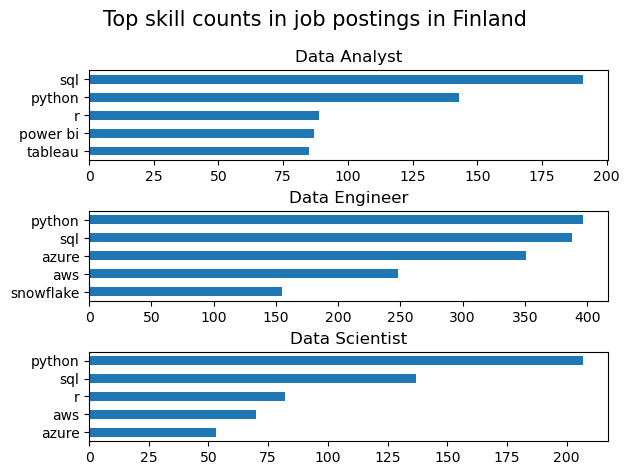

In [32]:
fig, ax = plt.subplots(len(job_titles), 1)

for i, job_title in enumerate(job_titles):
    df_plot =  df_skills_count[df_skills_count['job_title_short'] == job_title].head(5)
    df_plot.plot(kind='barh', x='job_skills', y='skill_count', ax=ax[i], title=job_title)
    ax[i].invert_yaxis()
    ax[i].set_ylabel('')
    ax[i].legend().set_visible(False)

    fig.suptitle('Top skill counts in job postings in Finland', fontsize=15)
    fig.tight_layout(h_pad=0.5)

In [35]:
df_job_title_count = df_FI['job_title_short'].value_counts().reset_index(name='jobs_total')

In [45]:
df_skills_perc = pd.merge(df_skills_count, df_job_title_count, how='left', on='job_title_short')

df_skills_perc['skill_percent'] = 100 * df_skills_perc['skill_count'] / df_skills_perc['jobs_total']

df_skills_perc.head()

,job_skills,job_title_short,skill_count,jobs_total,skill_percent
0,python,Data Engineer,397,699,56.795422
1,sql,Data Engineer,388,699,55.507868
2,azure,Data Engineer,351,699,50.214592
3,aws,Data Engineer,248,699,35.479256
4,python,Data Scientist,207,339,61.061947


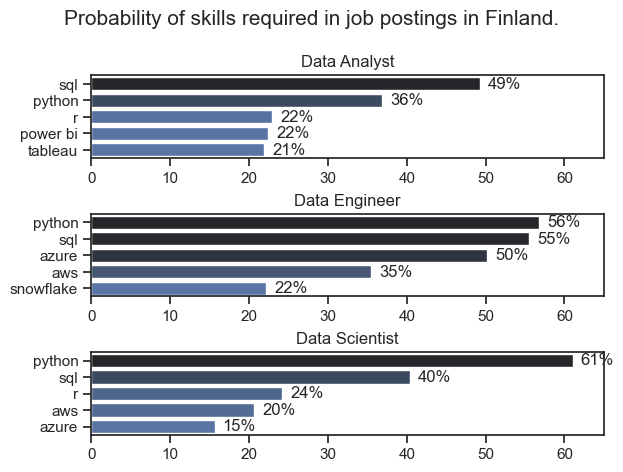

In [ ]:
fig, ax = plt.subplots(len(job_titles), 1)

sns.set_theme(style='ticks')

for i, job_title in enumerate(job_titles):
    df_plot =  df_skills_perc[df_skills_perc['job_title_short'] == job_title].head(5)
    sns.barplot(data=df_plot, x='skill_percent', y='job_skills', ax=ax[i], hue='skill_count', palette='dark:b_r')
    ax[i].set_title(job_title)
    ax[i].set_ylabel('')
    ax[i].set_xlabel('')
    ax[i].get_legend().remove()
    ax[i].set_xlim(0,65)

    for n, v in enumerate(df_plot['skill_percent']):
       ax[i].text(v + 1, n, f'{int(v)}%', va='center') #first v is the horizontal, last v is up and down. Changing to int to get rid of decimals.

    fig.suptitle('Probability of skills required in job postings in Finland.', fontsize=15)
    fig.tight_layout(h_pad=0.5)